In [72]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
from datetime import datetime, timedelta
import matplotlib.dates as mdates
import os
import urllib.request
import random
from scipy.optimize import curve_fit
from scipy.interpolate import interp1d
from numpy import trapezoid
from scipy.signal import argrelmin
import seaborn as sns
sns.set_theme(style = 'darkgrid')

In [73]:
# import panel data function
def Import_Panel_Data(year, day):
    InputPath = '../DataFolder'
    input_1 = year
    input_2 = day
    # --------REAL PANEL DATA-------------
    #Read the CSV files based on user input
    file_101 = pd.read_csv(f"{InputPath}/spo_dev101_{input_1}_{input_2}.csv",delimiter=',')
    file_103 = pd.read_csv(f"{InputPath}/spo_dev103_{input_1}_{input_2}.csv",delimiter=',')
    
    # Rename the Device ID column to voltage and Voltage to Current
    file_101.rename(columns = {'Device ID': 'V', 'Voltage': 'A'}, inplace=True)
    file_103.rename(columns = {'Device ID': 'V', 'Voltage': 'A'}, inplace=True) # There is a mismatch in the file so voltage column contains current and Device ID contains voltage
    
    # Each file has the data for more than just the day it is. We want to remove these extra dataS
    
    def date2num(date_str): # Renamed 'date' to 'date_str' to avoid confusion with the datetime.date object
        # 26 # first conver the xxxx-xx-xx format to date(xxxx, xx, xx)
    
        # You can skip splitting the string and go directly to parsing:
        date_object = datetime.strptime(date_str, '%Y-%m-%d').date()
        
        # 29 # return the day of the year (%j) as an integer
        # The strftime method returns a string, so we convert it to an integer.
        return int(date_object.strftime('%j'))
    # print(f'DEBUG: {input_2}')
    date = file_101['Date']
    NumberDate = date.apply(date2num)
    mask_to_keep =  NumberDate <= int(input_2)
    file_101 = file_101[mask_to_keep]
    # print(f'DEBUG: {mask_to_keep}')
    # print(f'DEBUG: {NumberDate}')
    
    date = file_103['Date']
    NumberDate = date.apply(date2num)
    mask_to_keep = NumberDate <= int(input_2)
    file_103 = file_103[mask_to_keep]
    
    #Extract time, voltage and current data
    
    time_101 = file_101['Time']
    voltage_101 = file_101['V'] 
    current_101 = file_101['A'] 
    
    time_103 = file_103['Time']
    voltage_103 = file_103['V'] 
    current_103 = file_103['A'] 
    
    power_101 = voltage_101 * current_101
    power_103 = voltage_103 * current_103
    # -----------------------------

    # print(f'len(power_101) = {len(power_101)}')
    return voltage_101, current_101, voltage_103, current_103, time_101, time_103

    

In [74]:
year = 25
day = 345
voltage_101, current_101, voltage_103, current_103, time_101, time_103 = Import_Panel_Data(year, day)




/var/folders/zk/p32hf16n3rnbx31r3xbsvc4m0000gn/T/ipykernel_48272/1898961481.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


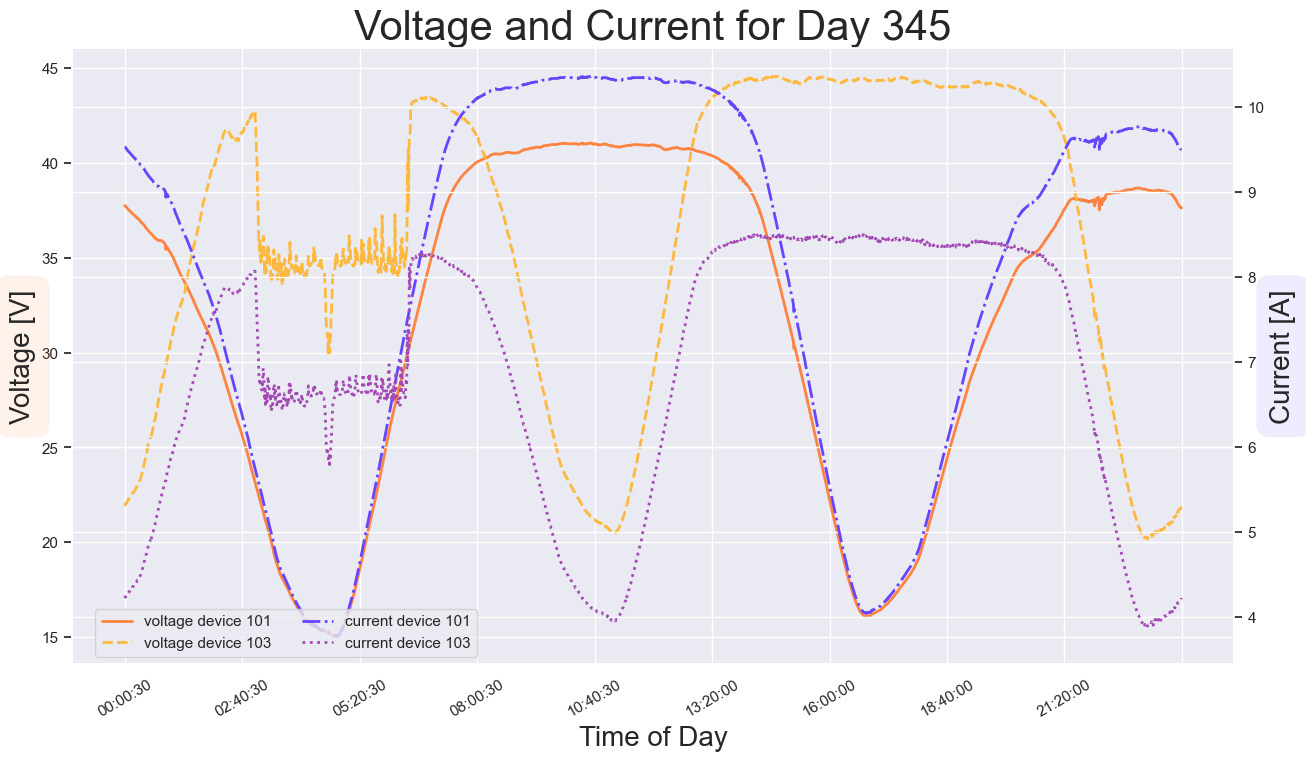

In [124]:

fig, ax1 = plt.subplots(figsize = (15,8))
ax1.plot(time_101, voltage_101, label = 'voltage device 101', color = '#ff8340', linewidth = 2, linestyle = '-')
ax1.plot(time_103, voltage_103, label = 'voltage device 103', color = '#ffb940', linewidth = 2, linestyle = '--')
ax1.set_ylabel('Voltage [V]', fontsize = 20, bbox=dict(facecolor='#ff8340', alpha=0.1, edgecolor='none', boxstyle='round,pad=0.5'))
ax1.set_xlabel('Time of Day', fontsize = 20)
title = f'Voltage and Current for Day {day}'
ax1.set_title(title, fontsize = 30)
ax1.grid('on')
ax1.set_xticks(np.linspace(0,len(time_101), 10))
ax1.tick_params(axis = 'x', rotation = 30)
ax2 = ax1.twinx()
ax2.plot(time_101, current_101, label = 'current device 101', color = '#6745ff', linewidth = 2, linestyle = '-.')
ax2.plot(time_103, current_103, label = 'current device 103', color = '#a34ab5', linewidth = 2, linestyle = ':')
ax2.set_ylabel('Current [A]', fontsize = 20, bbox=dict(facecolor='#6745ff', alpha=0.1, edgecolor='none', boxstyle='round,pad=0.5'))

# ax1.set_ylim(-10, 50)
# ax2.set_ylim(3, 15)
fig.legend(loc='lower right', bbox_to_anchor=(0.4, .11), ncols=2)

fig.show()

fig.savefig(title)

